In [1]:
from scipy.stats import rankdata 
import numpy as np
from MCRNI import MCRNI
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from plot import compute_mcrni_array, init_mcrni_plot, add_mcrni_curve #, show_mcrni_plot



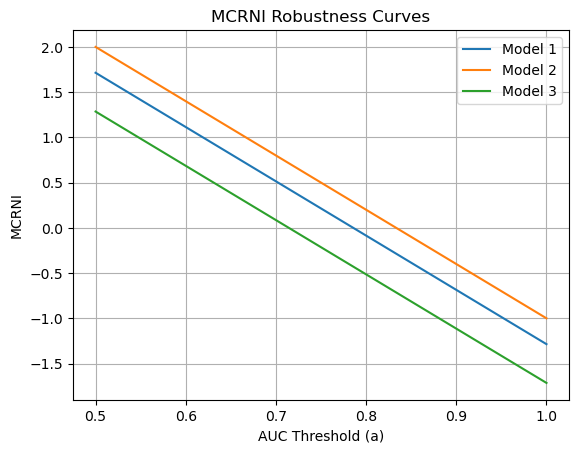

In [21]:
# Simulated small dataset
y_true = [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0,0, 0]  # 5 positives, 4 negatives
y1 = [92, 90, 80, 87, 95, 90, 85, 92, 86, 81, 78, 45, 30]  # Example scores
y2 = [93, 87, 82, 83, 97, 90, 85, 96, 82, 70, 70, 44, 32]  # Example scores
y3 = [94, 86, 85, 83, 97, 60, 85, 97, 83, 84, 65, 30, 29]  # Example scores

# Create models
model1 = MCRNI(y_true, y1)
model1.name = "Model 1"

model2 = MCRNI(y_true, y2)
model2.name = "Model 2"

model3 = MCRNI(y_true, y3)
model3.name = "Model 3"
auc_grid = np.linspace(0.5, 1.0, 50)
# print(auc_grid)
arr1 = compute_mcrni_array(model1, auc_grid)
arr2 = compute_mcrni_array(model2, auc_grid)
arr3 = compute_mcrni_array(model3, auc_grid)

# Shared AUC grid

#print(arr1)
#print(arr2)
#print(arr3)
# Initialize plot
fig, ax = init_mcrni_plot( arr1, auc_grid, "Model 1")

# Add others one by one
add_mcrni_curve(ax, arr2, auc_grid, "Model 2")
add_mcrni_curve(ax, arr3, auc_grid, "Model 3")

# Show
#show_mcrni_plot(ax)

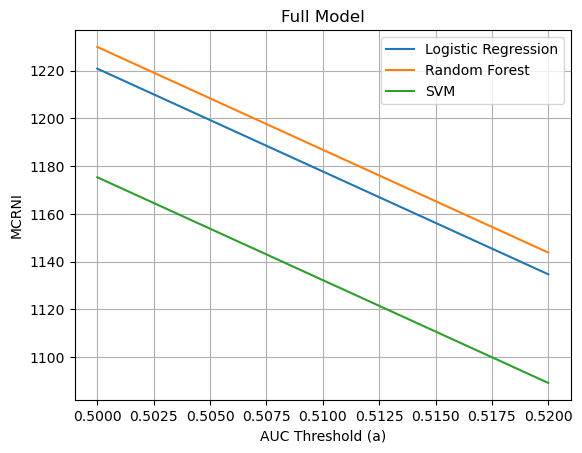

In [8]:
df = pd.read_csv("/Users/shimengdai/Dropbox/Michigan State/Papers/MCRNI/MCRNI_code/mcrni/input_data/predictions_wide_full.csv")

y_true = df["dropout"]

arr_log = df["pred_logreg_proba"]

arr2_rf = df["pred_rf_proba"]

arr3_svm = df["pred_svm_proba"]

model1 = MCRNI(y_true, arr_log)
model2 = MCRNI(y_true, arr2_rf)
model3 = MCRNI(y_true, arr3_svm)


auc_grid = np.linspace(0.5, 0.52, 50)
# print(auc_grid)
arr1 = compute_mcrni_array(model1, auc_grid)
arr2 = compute_mcrni_array(model2, auc_grid)
arr3 = compute_mcrni_array(model3, auc_grid)

fig, ax = init_mcrni_plot( arr1, auc_grid, label = "Logistic Regression", title = "Full Model")
add_mcrni_curve(ax, arr2, auc_grid, "Random Forest")
add_mcrni_curve(ax, arr3, auc_grid, "SVM")


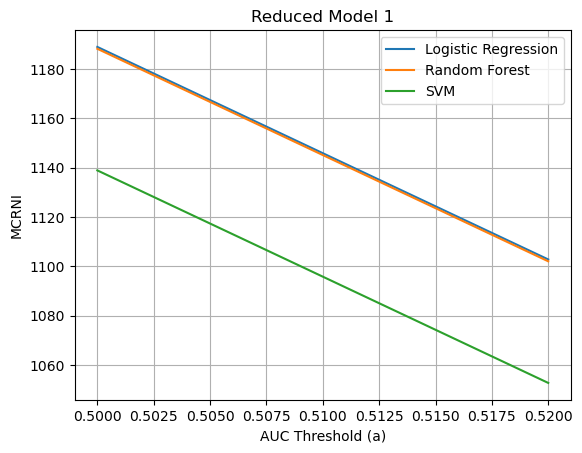

In [9]:
df = pd.read_csv("/Users/shimengdai/Dropbox/Michigan State/Papers/MCRNI/MCRNI_code/mcrni/input_data/predictions_wide_no_math.csv")

y_true = df["dropout"]

arr_log = df["pred_logreg_proba"]

arr2_rf = df["pred_rf_proba"]

arr3_svm = df["pred_svm_proba"]

model1 = MCRNI(y_true, arr_log)
model2 = MCRNI(y_true, arr2_rf)
model3 = MCRNI(y_true, arr3_svm)


auc_grid = np.linspace(0.5, 0.52, 50)
# print(auc_grid)
arr1 = compute_mcrni_array(model1, auc_grid)
arr2 = compute_mcrni_array(model2, auc_grid)
arr3 = compute_mcrni_array(model3, auc_grid)

fig, ax = init_mcrni_plot( arr1, auc_grid, label = "Logistic Regression", title = "Reduced Model 1")
add_mcrni_curve(ax, arr2, auc_grid, "Random Forest")
add_mcrni_curve(ax, arr3, auc_grid, "SVM")


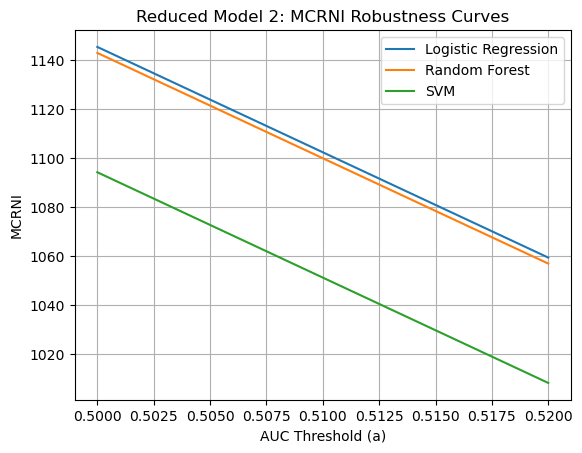

In [10]:
df = pd.read_csv("/Users/shimengdai/Dropbox/Michigan State/Papers/MCRNI/MCRNI_code/mcrni/input_data/predictions_wide_without2.csv")

y_true = df["dropout"]

arr_log = df["pred_logreg_proba"]

arr2_rf = df["pred_rf_proba"]

arr3_svm = df["pred_svm_proba"]

model1 = MCRNI(y_true, arr_log)
model2 = MCRNI(y_true, arr2_rf)
model3 = MCRNI(y_true, arr3_svm)


auc_grid = np.linspace(0.5, 0.52, 50)
# print(auc_grid)
arr1 = compute_mcrni_array(model1, auc_grid)
arr2 = compute_mcrni_array(model2, auc_grid)
arr3 = compute_mcrni_array(model3, auc_grid)

fig, ax = init_mcrni_plot( arr1, auc_grid, label = "Logistic Regression", title = "Reduced Model 2: MCRNI Robustness Curves")
add_mcrni_curve(ax, arr2, auc_grid, "Random Forest")
add_mcrni_curve(ax, arr3, auc_grid, "SVM")